In [1]:
import pandas as pd
import numpy as np
import requests
from io import StringIO
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder

In [2]:
#set out api_key
 
API_KEY = 'JHWM2SB-Y7D4EPT-NCD78X0-G96BVZK'


In [3]:
#get data from a single station 

def get_sm_data (ID,start,end,variables,res,API_KEY):
    
    #create our base url for the airquality egg api 
    base_url = f"https://airqualityegg.com/api/v2/messages/device/{ID}"

    # Set up the query parameters for the API request
    params = {
        "apiKey": API_KEY,
        "format": "csv",  # Request data in CSV format but doesn't have to be csv 
        "start-date": start,
        "end-date": end,
        "resolution": f"PT{res}"  } # Add 'PT' prefix to resolution

    # Send GET request to the API
    response = requests.get(base_url, params=params, timeout=20) 

    # Raise an exception for bad responses
    response.raise_for_status()

    # Parse the CSV response into a pandas DataFrame
    data = pd.read_csv(StringIO(response.text))
    
    # Print shape of received data for reference 
    print(f"Received data shape: {data.shape}")

    # Filter the DataFrame to include only the requested variables 
    available_vars = [var for var in variables if var in data.columns]

    # Return the filtered DataFrame with time column and available variables
    return data[['time'] + available_vars]

Retrieve data from the Air Quality Egg API for a specific device and time range.

The  get_sm_data function takes 6 arguments: 

    ID(str): 5 letter identifier for the soil moisture device    
    start (str): Start date-time in ISO-8601 format (e.g., '2024-08-01T00:00:00.000Z')
    end (str): End date-time in ISO-8601 format
    variables (list): List of data variables to retrieve
    resolution (str): Time resolution of data ('30M' for 30 minutes, '1H' for 1 hour)
    API_Key(str):28 digit key in formatt 0000000-0000000-0000000-0000000

and returns a pandas DataFrame containing data from a given sensor for the variables we requested 

In [4]:
#to get data from multimple sensors be wary, very slow 

def get_multi_sm_data(IDs, start, end, variables, res, API_KEY):

    if isinstance(IDs, str):
        IDs = [IDs]  # Convert ID to list 

    data_dict = {}

    for ID in IDs:
        base_url = f"https://airqualityegg.com/api/v2/messages/device/{ID}"
        params = {
            "apiKey": API_KEY,
            "format": "csv",
            "start-date": start,
            "end-date": end,
            "resolution": f"PT{res}"
        }

        response = requests.get(base_url, params=params, timeout=20)
        response.raise_for_status()
        data = pd.read_csv(StringIO(response.text))
        print(f"Received data shape for sensor {ID}: {data.shape}")

        available_vars = [var for var in variables if var in data.columns]
        data_dict[ID] = data[['time'] + available_vars]

#return the data as a data dictionary with all of the columns of each sensor 
    return data_dict

The  get_multi_sm_data function takes 6 arguments: 

    IDs(list of str): list of 5 letter identifiers for the soil moisture device    
    start (str): Start date-time in ISO-8601 format (e.g., '2024-08-01T00:00:00.000Z')
    end (str): End date-time in ISO-8601 format
    variables (list): List of data variables to retrieve
    resolution (str): Time resolution of data ('30M' for 30 minutes, '1H' for 1 hour)
    API_Key(str):28 digit key in formatt 0000000-0000000-0000000-0000000

Returns:
    dict: Dictionary with station IDs as keys and pandas DataFrames as values.
    

In [5]:
#plot data from a single sensor 

def plot_sm_data(data,ID):
    """
    Plot the Air Quality Egg data with time on the x-axis in D/M/Y format.
    Args:
        data (pandas.DataFrame): DataFrame containing the data to plot.
    """
    # Convert the 'time' column to datetime so I can reformat it for plotting 
    data['time'] = pd.to_datetime(data['time'])
    
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plot soil moisture data
    soil_moisture = data['soilmoisture[percent]']
    ax.plot(data['time'], soil_moisture, label=str(ID), color='#1f77b4')
    
    # Customize the plot
    ax.set_xlabel('Date')
    ax.set_ylabel('Volumetric Water Content (%)')
    ax.set_title('Soil Moisture Over Time')
    
    
    # Format x-axis
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y'))
    plt.xticks(rotation=0)
    
    # Add gridlines
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Add legend and mean value annotation
    ax.legend(loc='upper right')
 
    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()   

the plot_sm_data function takes 2 arguments:

    data(Dataframe): the data the previous function pulled from api
    ID(Str):Identifier for the soil moisture device.

converts the 'time' column of the data dataframe into a datetime object that can be operated on

returns: a plot of the soil moisture for the given time period against the datetime in DD/MM/YYYY format 

In [6]:
#to plot multiple ssensors
def plot_multi_sensor_data(sensor_ids, start, end, variables, res, API_KEY):
    """
    Retrieve and plot the Air Quality Egg data for multiple sensors with time on the x-axis in D/M/Y format."""
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(20, 8))
    
    # Color cycle for different sensors because I couldn't decide on colors 
    colors = np.random.rand(len(sensor_ids), 3)
    
    for sensor_id, color in zip(sensor_ids, colors):
        # Retrieve data for the current sensor
        data = get_sm_data(sensor_id, start, end, variables, res, API_KEY)
        
        # Convert the 'time' column to datetime 
        data['time'] = pd.to_datetime(data['time'])
        
        # Plot soil moisture data vs time 
        if 'soilmoisture[percent]' in data.columns:
            soil_moisture = data['soilmoisture[percent]']
            ax.plot(data['time'], soil_moisture, label=f'Sensor {sensor_id}', color=color)
            
        else:
            print(f"Warning: 'soilmoisture[percent]' not found for Sensor {sensor_id}")
    
    # label plot 
    ax.set_xlabel('Date')
    ax.set_ylabel('Volumetric Water Content (%)')
    ax.set_title('Soil Moisture Over Time')
    
    # Format x-axis so date is in the format i want 
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y'))
    plt.xticks(rotation=45)
    
    # Add gridlines 
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Add legend
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()


 the  plot_multi_sensor_data takes 6 arguments:
   
    sensor_ids (list): List of sensor IDs to retrieve and plot data for.
    start (str): Start date for data retrieval in YYYY-MM-DD format.
    end (str): End date for data retrieval in YYYY-MM-DD format.
    variables (list): List of variables to retrieve and plot.
    res (str): Resolution for data retrieval.
    API_KEY (str): API key for accessing the Air Quality Egg API.
    
Retrieve and plot the Air Quality Egg data for multiple sensors with time on the x-axis in D/M/Y format.

Received data shape: (1526, 5)
Received data shape: (1537, 5)
Received data shape: (1498, 5)


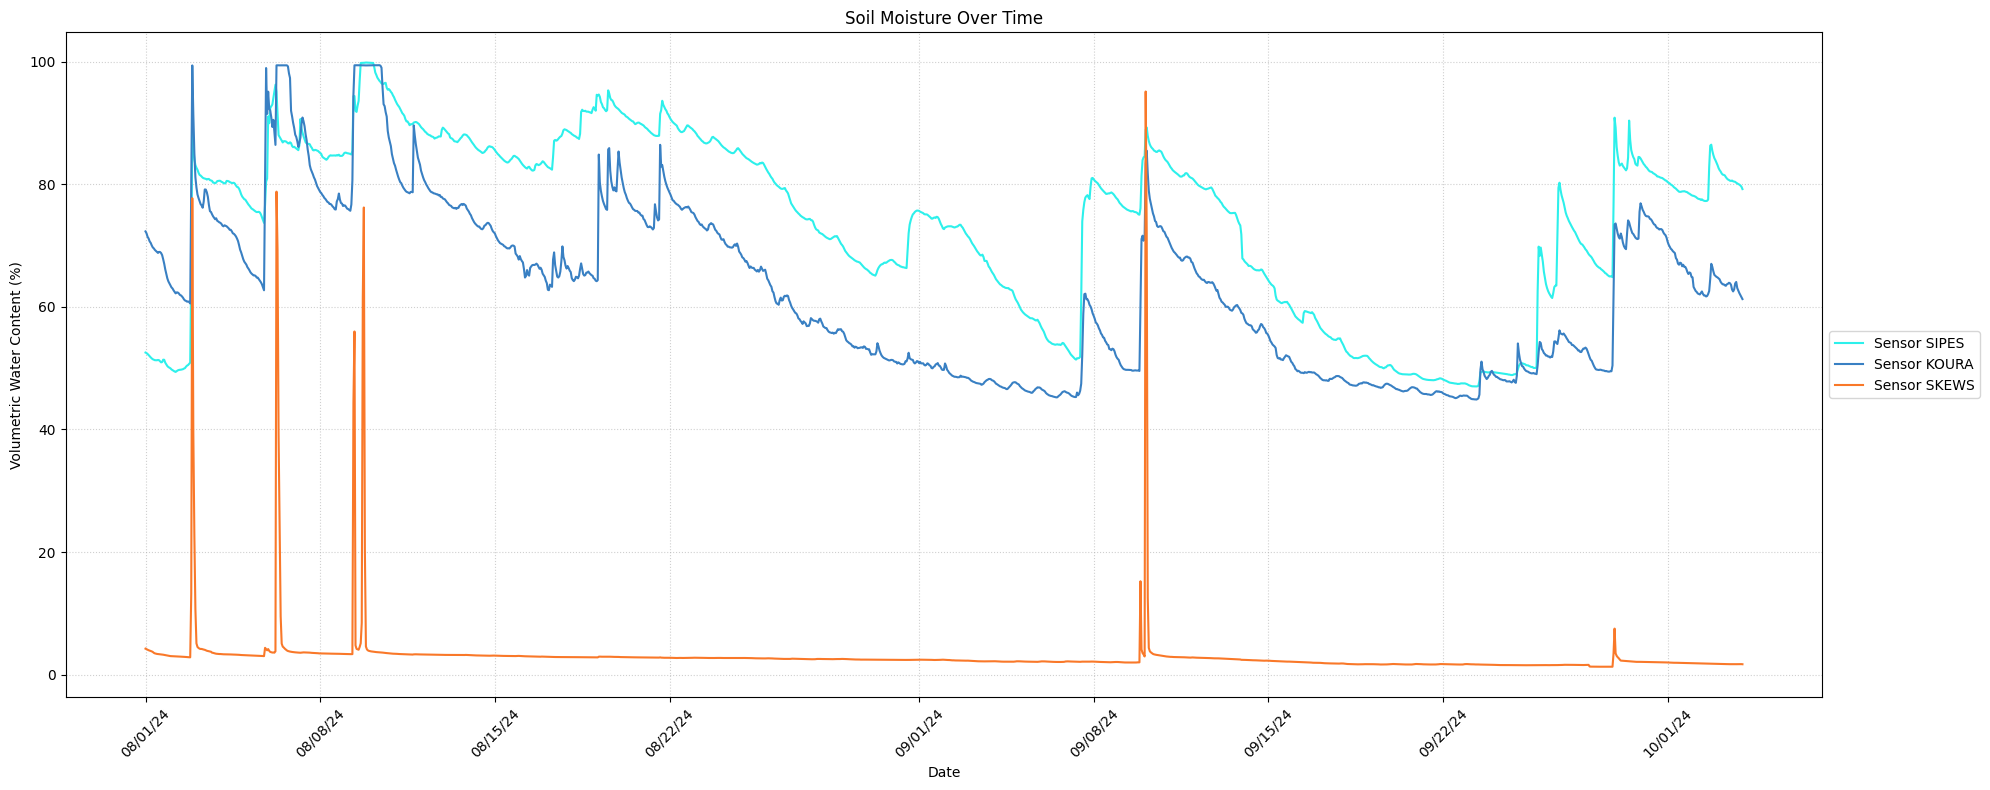

In [7]:
## example use of the code 

# Define the variables we want to retrieve
variables = ['soilmoisture[percent]']
ID = "SIPES"  
start = "2024-08-01T00:00:00.000Z"
end = "2024-10-04T00:00:00.000Z"
res = "1H"  # 
sensor_ids=["SIPES","KOURA","SKEWS"]

# Plot the sensor data
plot_multi_sensor_data(sensor_ids, start, end, variables, res, API_KEY)